# Task 4 — Process Improvement Proposal: workflow simulation

Client: **Apex Global Investments** (hypothetical) — high-frequency trading, $1.5bn annual volume.
Current trade workflow (Client Profile Reference Sheet): data entry ~15 min → cross-system validation ~20 min →
compliance approval ~25 min → report generation ~30 min = **90 min**, with a **12% reconciliation error rate**
and about **$500,000 of missed opportunities last quarter**.

This notebook reproduces every number, table and chart in `Process_Improvement_Proposal.tex`:

1. Step times from the profile, and where the time goes → `figures/fig1_step_times.pdf`
2. Monte Carlo simulation of 10,000 trades, current vs. automated → `figures/table1_simulation.tex`, `figures/fig2_distribution.pdf`
3. Impact by phase of the roll-out → `figures/table2_phases.tex`
4. Cost–benefit and sensitivity → `figures/table3_costbenefit.tex`

> **Assumptions.** The step means, the 12% error rate and the $500k figure come from the profile sheet. Variability,
> rework time, the performance of the automated steps and the costs are **stated assumptions**, gathered in one
> cell so they can be challenged and re-run. Results show the size of the gain, not a guarantee.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)          # fixed seed: results are reproducible
N = 10_000                               # simulated trades

# Two-series palette (validated: lightness, chroma, CVD separation, normal-vision floor)
CUR, PRO = "#D9822B", "#2A55B0"          # current = orange, automated = blue
INK, MUTED = "#222222", "#666666"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "xtick.color": MUTED, "ytick.color": MUTED})

def tex(v, fmt="{:.1f}", sign=False):
    s = (("{:+" + fmt[2:]) if sign else fmt).format(v)
    return s.replace("-", r"\textminus{}")

## 1. Where the time goes (Client Profile Reference Sheet)

In [2]:
STEPS = ["Data entry", "Cross-system validation", "Compliance approval", "Report generation"]
profile = pd.Series([15, 20, 25, 30], index=STEPS, name="Minutes (profile)")
assert profile.sum() == 90                       # matches 'average trade execution time: 90 minutes'
pd.DataFrame({"Minutes": profile, "Share (%)": (100 * profile / profile.sum()).round(1),
              "Before execution?": ["yes", "yes", "yes", "no (post-trade)"]})

,Minutes,Share (%),Before execution?
Data entry,15,16.7,yes
Cross-system validation,20,22.2,yes
Compliance approval,25,27.8,yes
Report generation,30,33.3,no (post-trade)


Three of the four steps happen **before** the trade can be executed: 60 minutes of manual hand-offs.
Compliance approval is the longest pre-trade step (25 min) and cross-system validation is where the 12% of errors appear.

## 2. Assumptions

In [3]:
A = dict(
    cv=0.30,                    # variability of manual step times (coefficient of variation)
    err_current=0.12,           # reconciliation error rate (profile sheet)
    rework_current=(20, 25),    # an error means re-validating and re-checking with compliance (min)
    # --- automated workflow ---
    entry_auto=1.0,             # API / straight-through capture of trade details (min)
    valid_auto=2.0,             # rule-based reconciliation engine, exceptions only (min)
    err_auto=0.02,              # residual exception rate after automated matching
    rework_auto=10,             # analyst resolves an exception flagged by the engine (min)
    auto_approve=0.85,          # share of trades passing automated pre-trade compliance rules
    approve_auto=1.0,           # time when rules pass (min)
    approve_manual_exc=15,      # officer reviews only the flagged exceptions (min)
    report_auto=2.0,            # templated report generated and distributed automatically (min)
    missed_q=500_000,           # missed opportunities last quarter, $ (profile sheet)
)
pd.Series(A, dtype=object)

cv                         0.3
err_current               0.12
rework_current        (20, 25)
entry_auto                 1.0
valid_auto                 2.0
err_auto                  0.02
rework_auto                 10
auto_approve              0.85
approve_auto               1.0
approve_manual_exc          15
report_auto                2.0
missed_q                500000
dtype: object

In [4]:
def gamma(mean, n, cv=A["cv"]):
    k = 1 / cv**2                                  # shape; mean = k * theta
    return rng.gamma(k, mean / k, n)

def simulate(entry, valid, approve, report, err_rate, rework):
    """Times in minutes for N trades; returns pre-trade time, end-to-end time and error flags."""
    err = rng.random(N) < err_rate
    rw = rework if np.isscalar(rework) else rng.uniform(*rework, N)
    pre = entry + valid + approve + err * rw
    return pd.DataFrame({"pre_trade": pre, "end_to_end": pre + report, "error": err})

current = simulate(gamma(15, N), gamma(20, N), gamma(25, N), gamma(30, N),
                   A["err_current"], A["rework_current"])

passed = rng.random(N) < A["auto_approve"]
approve_new = np.where(passed, gamma(A["approve_auto"], N, 0.2), gamma(A["approve_manual_exc"], N))
automated = simulate(gamma(A["entry_auto"], N, 0.2), gamma(A["valid_auto"], N, 0.2), approve_new,
                     gamma(A["report_auto"], N, 0.2), A["err_auto"], A["rework_auto"])

def summary(df):
    return {"Average time to execution (min)": df["pre_trade"].mean(),
            "95th percentile time to execution (min)": df["pre_trade"].quantile(0.95),
            "Average end-to-end time incl. report (min)": df["end_to_end"].mean(),
            "Reconciliation error rate (%)": 100 * df["error"].mean()}

sim = pd.DataFrame({"Current": summary(current), "Automated": summary(automated)})
sim["Change (%)"] = 100 * (sim["Automated"] / sim["Current"] - 1)
sim.round(1)

,Current,Automated,Change (%)
Average time to execution (min),62.7,6.3,-89.9
95th percentile time to execution (min),86.8,20.1,-76.9
Average end-to-end time incl. report (min),92.7,8.3,-91.0
Reconciliation error rate (%),12.1,1.9,-84.4


In [5]:
lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
         r"\textbf{Metric (10{,}000 simulated trades)} & \textbf{Current} & \textbf{Automated} & \textbf{Change} \\",
         r"\midrule"]
labels = {"Average time to execution (min)": "Average time to execution (min)",
          "95th percentile time to execution (min)": "Slowest 5\\% of trades: time to execution (min)",
          "Average end-to-end time incl. report (min)": "End-to-end time incl.\\ report (min)",
          "Reconciliation error rate (%)": "Reconciliation error rate (\\%)"}
for k, lab in labels.items():
    r = sim.loc[k]
    lines.append(f"{lab} & {tex(r['Current'])} & {tex(r['Automated'])} & {tex(r['Change (%)'], '{:.0f}', sign=True)}\\% \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(FIG / "table1_simulation.tex").write_text("\n".join(lines))
print("\n".join(lines))

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Metric (10{,}000 simulated trades)} & \textbf{Current} & \textbf{Automated} & \textbf{Change} \\
\midrule
Average time to execution (min) & 62.7 & 6.3 & \textminus{}90\% \\
Slowest 5\% of trades: time to execution (min) & 86.8 & 20.1 & \textminus{}77\% \\
End-to-end time incl.\ report (min) & 92.7 & 8.3 & \textminus{}91\% \\
Reconciliation error rate (\%) & 12.1 & 1.9 & \textminus{}84\% \\
\bottomrule
\end{tabular}


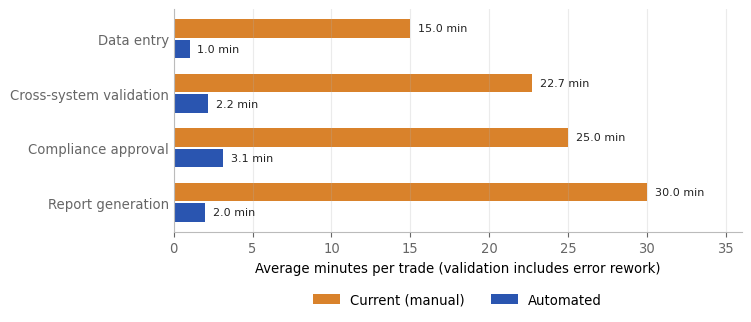

,Current,Automated
Data entry,15.0,1.0
Cross-system validation,22.7,2.2
Compliance approval,25.0,3.1
Report generation,30.0,2.0


In [6]:
# Figure 1 - average minutes per step, current vs automated (from the simulation)
step_cur = pd.Series([15, 20 + A["err_current"] * np.mean(A["rework_current"]), 25, 30], index=STEPS)
step_new = pd.Series([A["entry_auto"], A["valid_auto"] + A["err_auto"] * A["rework_auto"],
                      A["auto_approve"] * A["approve_auto"] + (1 - A["auto_approve"]) * A["approve_manual_exc"],
                      A["report_auto"]], index=STEPS)
fig, ax = plt.subplots(figsize=(7.6, 3.4))
y = np.arange(len(STEPS)); h = 0.38
for vals, off, col, lab in [(step_cur, -h/2, CUR, "Current (manual)"), (step_new, h/2, PRO, "Automated")]:
    bars = ax.barh(y + off, vals, height=h - 0.04, color=col, label=lab)
    for b, v in zip(bars, vals):
        ax.text(v + 0.5, b.get_y() + b.get_height()/2, f"{v:.1f} min", va="center", fontsize=8, color=INK)
ax.set_yticks(y, STEPS); ax.invert_yaxis(); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Average minutes per trade (validation includes error rework)"); ax.set_xlim(0, 36)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig1_step_times.pdf", bbox_inches="tight"); plt.show()
pd.DataFrame({"Current": step_cur, "Automated": step_new}).round(1)

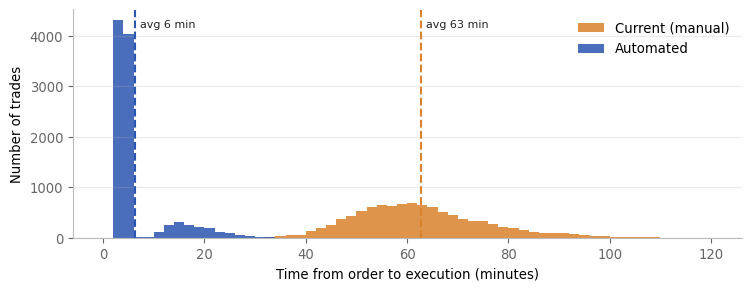

In [7]:
# Figure 2 - distribution of time to execution
fig, ax = plt.subplots(figsize=(7.6, 3.0))
bins = np.arange(0, 121, 2)
ax.hist(current["pre_trade"], bins=bins, color=CUR, alpha=0.85, label="Current (manual)")
ax.hist(automated["pre_trade"], bins=bins, color=PRO, alpha=0.85, label="Automated")
for df, col in [(current, CUR), (automated, PRO)]:
    m = df["pre_trade"].mean()
    ax.axvline(m, color=col, lw=1.5, ls="--")
    ax.text(m + 1, ax.get_ylim()[1] * 0.92, f"avg {m:.0f} min", color=INK, fontsize=8)
ax.set_xlabel("Time from order to execution (minutes)"); ax.set_ylabel("Number of trades")
ax.grid(axis="y", alpha=0.25); ax.legend(loc="upper right", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig2_distribution.pdf", bbox_inches="tight"); plt.show()

## 3. Impact by phase

The roll-out is phased because Apex has **limited IT resources**: each phase must work on its own and be measured before the next.

In [8]:
def run(entry_auto, valid_auto, approve_auto, report_auto):
    e = gamma(A["entry_auto"], N, 0.2) if entry_auto else gamma(15, N)
    v = gamma(A["valid_auto"], N, 0.2) if valid_auto else gamma(20, N)
    if approve_auto:
        ok = rng.random(N) < A["auto_approve"]
        a = np.where(ok, gamma(A["approve_auto"], N, 0.2), gamma(A["approve_manual_exc"], N))
    else:
        a = gamma(25, N)
    r = gamma(A["report_auto"], N, 0.2) if report_auto else gamma(30, N)
    err, rw = (A["err_auto"], A["rework_auto"]) if valid_auto else (A["err_current"], A["rework_current"])
    return simulate(e, v, a, r, err, rw)

phases = {
    "Today (manual)":                                   run(False, False, False, False),
    "Phase 1: reconciliation engine + auto reports":    run(False, True,  False, True),
    "Phase 2: + rule-based compliance pre-checks":      run(False, True,  True,  True),
    "Phase 3: + automated trade capture (API)":         run(True,  True,  True,  True),
}
ph = pd.DataFrame({k: summary(v) for k, v in phases.items()}).T
ph.round(1)

,Average time to execution (min),95th percentile time to execution (min),Average end-to-end time incl. report (min),Reconciliation error rate (%)
Today (manual),62.8,86.7,92.8,12.1
Phase 1: reconciliation engine + auto reports,42.2,57.6,44.2,2.0
Phase 2: + rule-based compliance pre-checks,20.2,34.7,22.2,2.1
Phase 3: + automated trade capture (API),6.3,19.7,8.3,1.8


In [9]:
lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
         r"\textbf{Stage} & \textbf{Time to execution} & \textbf{End-to-end} & \textbf{Error rate} \\", r"\midrule"]
for k, r in ph.iterrows():
    lines.append(f"{k} & {r['Average time to execution (min)']:.0f} min & {r['Average end-to-end time incl. report (min)']:.0f} min & "
                 f"{r['Reconciliation error rate (%)']:.1f}\\% \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(FIG / "table2_phases.tex").write_text("\n".join(lines))
print("\n".join(lines))

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Stage} & \textbf{Time to execution} & \textbf{End-to-end} & \textbf{Error rate} \\
\midrule
Today (manual) & 63 min & 93 min & 12.1\% \\
Phase 1: reconciliation engine + auto reports & 42 min & 44 min & 1.9\% \\
Phase 2: + rule-based compliance pre-checks & 20 min & 22 min & 2.1\% \\
Phase 3: + automated trade capture (API) & 6 min & 8 min & 1.8\% \\
\bottomrule
\end{tabular}


## 4. Cost–benefit

Missed opportunities are assumed to scale with the time a trade waits before execution. Because that link is
uncertain, three cases are shown: only 25%, 50% or 100% of the time saved turns into recovered opportunities.
Costs are illustrative (reconciliation and compliance-rules software, vendor-managed API integration, training).

In [10]:
annual_missed = 4 * A["missed_q"]                                    # $2.0m a year at today's run-rate
cut = 1 - sim.loc["Average time to execution (min)", "Automated"] / sim.loc["Average time to execution (min)", "Current"]
COST_Y1, COST_RUN = 400_000, 120_000                                     # $ year 1 (set-up + licences), $ per later year

rows = {}
for share in [0.25, 0.50, 1.00]:
    benefit = annual_missed * cut * share
    rows[f"{int(share*100)}% of time saved is recovered"] = {
        "Annual benefit ($k)": benefit / 1e3,
        "Year-1 net ($k)": (benefit - COST_Y1) / 1e3,
        "Payback (months)": 12 * COST_Y1 / benefit,
        "3-year net ($k)": (3 * benefit - COST_Y1 - 2 * COST_RUN) / 1e3,
    }
cb = pd.DataFrame(rows).T
print(f"Time to execution cut by {100*cut:.0f}%; missed opportunities today ~${annual_missed/1e6:.1f}m a year")
cb.round(1)

Time to execution cut by 90%; missed opportunities today ~$2.0m a year


,Annual benefit ($k),Year-1 net ($k),Payback (months),3-year net ($k)
25% of time saved is recovered,449.5,49.5,10.7,708.6
50% of time saved is recovered,899.1,499.1,5.3,2057.3
100% of time saved is recovered,1798.2,1398.2,2.7,4754.6


In [11]:
lines = [r"\begin{tabular}{@{}lrrrr@{}}", r"\toprule",
         r"\textbf{Scenario} & \textbf{Annual benefit} & \textbf{Year-1 net} & \textbf{Payback} & \textbf{3-year net} \\", r"\midrule"]
for k, r in cb.iterrows():
    lines.append(f"{k.replace('%', chr(92) + '%')} & \\${r['Annual benefit ($k)']:,.0f}k & \\${tex(r['Year-1 net ($k)'], '{:,.0f}')}k & "
                 f"{r['Payback (months)']:.1f} months & \\${tex(r['3-year net ($k)'], '{:,.0f}')}k \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
(FIG / "table3_costbenefit.tex").write_text("\n".join(lines))
print("\n".join(lines))

\begin{tabular}{@{}lrrrr@{}}
\toprule
\textbf{Scenario} & \textbf{Annual benefit} & \textbf{Year-1 net} & \textbf{Payback} & \textbf{3-year net} \\
\midrule
25\% of time saved is recovered & \$450k & \$50k & 10.7 months & \$709k \\
50\% of time saved is recovered & \$899k & \$499k & 5.3 months & \$2,057k \\
100\% of time saved is recovered & \$1,798k & \$1,398k & 2.7 months & \$4,755k \\
\bottomrule
\end{tabular}


## Reading

Automating the three pre-trade hand-offs removes most of the waiting time before a trade can be executed, and the
reconciliation engine replaces the step where errors originate. Even if only a quarter of the time saved turns into
recovered opportunities, the investment pays back within about a year under these assumptions.